In [2]:
import numpy as np

In [3]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import binned_statistic, gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# --- STYLE CONFIGURATION ---
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False, 
        'figure.frameon': True,
        'axes.linewidth': 2., 
        "axes.titlesize" : 20, 
        "axes.labelsize" : 20,
        "legend.fontsize" : 12, 
        'legend.fancybox': True, 
        'lines.linewidth': 2.5,
        'xtick.direction': 'in', 
        'ytick.direction': 'in',
        'xtick.top': True, 
        'ytick.right': True,
        'xtick.labelsize': 18, 
        'ytick.labelsize': 18
    }
    return font, rcnew

# Apply interactive backend and style
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [13]:
# ==============================================================================
# CELL 1: MULTI-RESOLUTION DATA LOADING & PRE-PROCESSING (TNG50)
# ==============================================================================
# 1. Define a dictionary with your resolution models. 
DATA_FILES = {
    'TNG50-2 (id 0)':  'data_for_variance/TNG50-2_z3_595Halos_DLAMode_Stratified_run0_seed42.pkl',
    #'TNG50-2_1 (previous)':  'data_grid/TNG50-2_z3_595Halos_DLAMode_Stratified.pkl',
    #'TNG50-2 (High Res)': 'data_grid/TNG50-2_z3_595Halos_DLAMode_Stratified.pkl'
}

HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# Dictionary to store the cleaned DataFrames
dfs_clean = {}
unique_radii = None

print("Loading Multi-Resolution Data...")
for model_name, file_path in DATA_FILES.items():
    if not os.path.exists(file_path):
        print(f" [!] Warning: {file_path} not found. Skipping {model_name}.")
        continue
        
    print(f" -> Processing {model_name}...")
    df = pd.read_pickle(file_path)
    df['halo_mass_msun'] = df['halo_mass'] * MASS_CONVERSION_FACTOR
    
    # Clean data
    df_c = df.dropna(subset=['halo_mass_msun', 'eq_width', 'log_n_hi']).copy()
    df_c['r_mult_round'] = df_c['r_multiplier'].round(2)
    dfs_clean[model_name] = df_c
    
    # Extract unique radii (assuming all models share the same geometry)
    if unique_radii is None:
        unique_radii = np.sort(df_c['r_mult_round'].unique())

n_panels = len(unique_radii)
n_models = len(dfs_clean)

print("-" * 40)
print(f"Successfully loaded {n_models} resolution models.")
print(f"Impact parameters detected: {unique_radii}")

Loading Multi-Resolution Data...
 -> Processing TNG50-2 (id 0)...
----------------------------------------
Successfully loaded 1 resolution models.
Impact parameters detected: [0.   0.01 0.02 0.03 0.04 0.05 0.07 0.1  0.14 0.19 0.26 0.37 0.51 0.7
 0.97 1.35 1.87 2.6  3.61 5.  ]


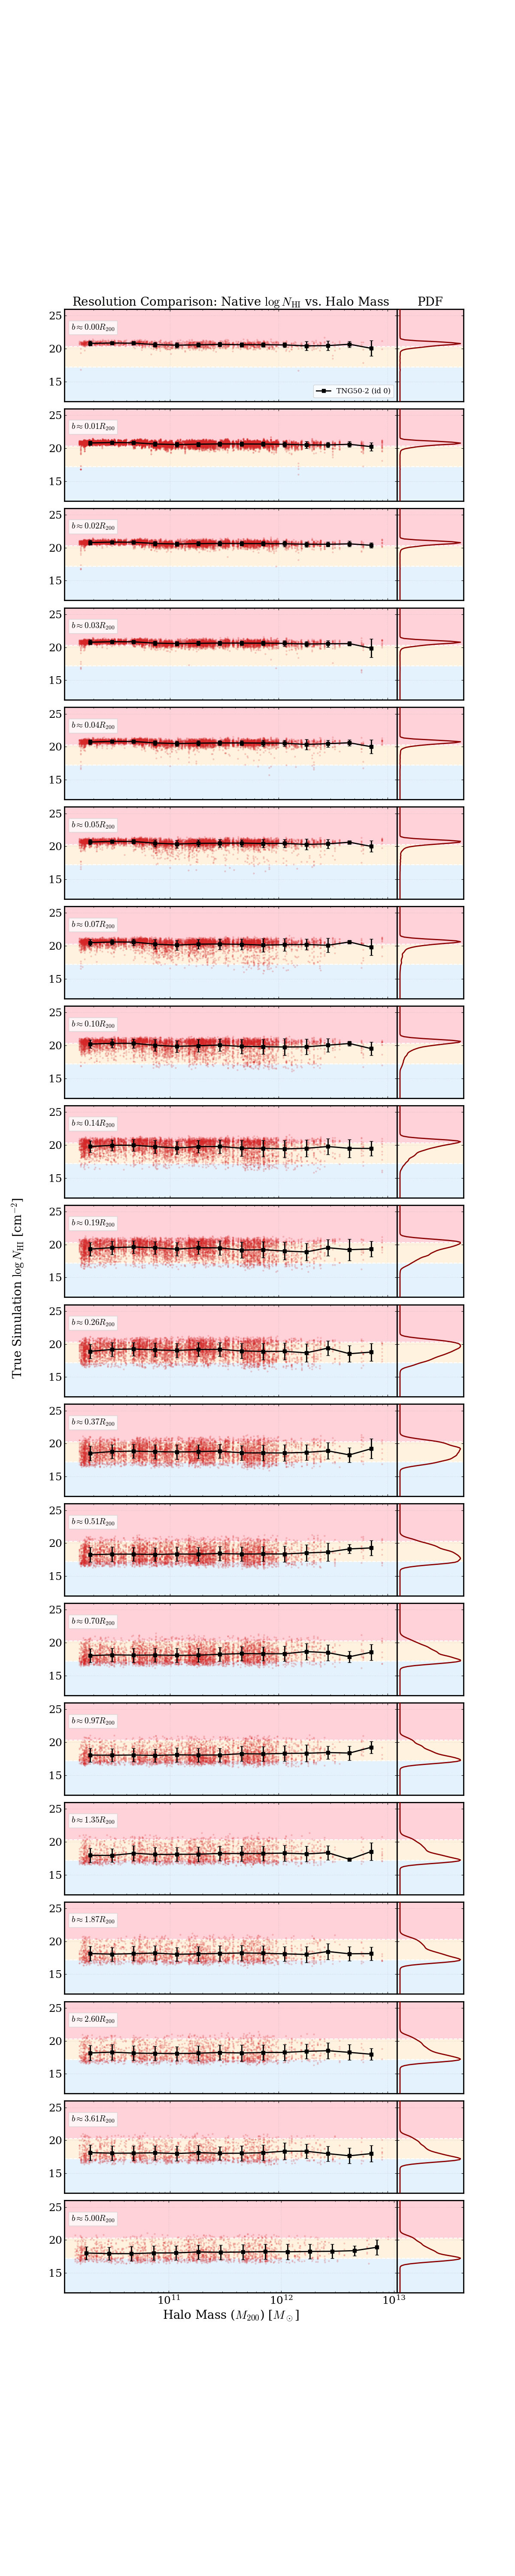

In [14]:
# ==============================================================================
# CELL 2: MULTI-RESOLUTION COMPARISON - NATIVE COLUMN DENSITY (SCATTER & PDF)
# ==============================================================================
fig_nhi, axes_nhi = plt.subplots(n_panels, 2, figsize=(12, 3 * n_panels), sharey=True, 
                                 gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.0, 'hspace': 0.08})
if n_panels == 1: axes_nhi = np.array([axes_nhi])

# Background region colors
c_forest = '#E3F2FD'  # Soft Blue
c_lls    = '#FFF3E0'  # Soft Orange
c_dla    = '#FFD1D8'  # Slightly darker Soft Red/Pink

# Style mapping for resolution models (Expandable)
# Index 0 (TNG50-4): Red mean, Dark Red PDF, Solid line
# Index 1 (TNG50-3): Blue mean, MidnightBlue PDF, Dashed line
# Index 2 (TNG50-2): Green mean, DarkGreen PDF, Dotted line
colors_scat = ['tab:red', 'tab:blue', 'tab:green']
colors_mean = ['black', 'dodgerblue', 'forestgreen']
colors_pdf  = ['darkred', 'midnightblue', 'darkgreen']
line_styles = ['-', '--', ':']
markers     = ['s', 'o', '^']

for i, b_val in enumerate(unique_radii):
    ax_main, ax_hist = axes_nhi[i, 0], axes_nhi[i, 1]
    
    # 1. Background Regions
    for ax in [ax_main, ax_hist]:
        ax.axhspan(12.0, 17.2, color=c_forest, zorder=0)
        ax.axhspan(17.2, 20.3, color=c_lls, zorder=0)
        ax.axhspan(20.3, 26.0, color=c_dla, zorder=0)
        ax.axhline(17.2, color='white', ls='--', lw=1.5, zorder=0)
        ax.axhline(20.3, color='white', ls='--', lw=1.5, zorder=0)
        ax.grid(True, ls=':', alpha=0.4)

    # 2. Iterate through loaded models to overlay data
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_s = colors_scat[m_idx % len(colors_scat)]
        c_m = colors_mean[m_idx % len(colors_mean)]
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        mkr = markers[m_idx % len(markers)]
        
        df_b = df_model[df_model['r_mult_round'] == b_val]
        df_valid = df_b[(df_b['log_n_hi'] > 1.0) & (df_b['halo_mass_msun'] > 0.0)] 
        
        # Raw Scatter (Very low alpha)
        ax_main.scatter(df_b['halo_mass_msun'], df_b['log_n_hi'], 
                        s=5, alpha=0.15, color=c_s, zorder=1)
        
        if len(df_valid) > 0:
            # Binned Statistics
            bins = np.logspace(np.log10(df_valid['halo_mass_msun'].min()), np.log10(df_valid['halo_mass_msun'].max()), 15)
            means, edges, _ = binned_statistic(df_valid['halo_mass_msun'], df_valid['log_n_hi'], 'mean', bins=bins)
            stds, _, _ = binned_statistic(df_valid['halo_mass_msun'], df_valid['log_n_hi'], 'std', bins=bins)
            centers = np.sqrt(edges[:-1] * edges[1:])
            
            # Mean line overlay
            ax_main.errorbar(centers, means, yerr=stds, fmt=f'{mkr}{ls}', color=c_m, 
                             markersize=6, capsize=3, lw=2, zorder=5)
            
            # Marginal Distribution (PDF) - No fill, just lines for clean comparison
            if len(df_valid) > 1:
                kde = gaussian_kde(df_valid['log_n_hi'])
                y_grid = np.linspace(12.0, 26.0, 100)
                ax_hist.plot(kde(y_grid), y_grid, color=c_p, lw=2, ls=ls, zorder=3)

    # 3. Aesthetics
    ax_hist.set_xticks([])
    ax_main.set_xscale('log')
    if i < n_panels - 1: 
        ax_main.tick_params(labelbottom=False)
    
    ax_main.text(0.02, 0.85, rf"$b \approx {b_val:.2f} R_{{200}}$", 
                 transform=ax_main.transAxes, bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgray'), va='top')
    
    if i == 0:
        ax_main.set_title(r"Resolution Comparison: Native $\log N_{\rm HI}$ vs. Halo Mass")
        ax_hist.set_title("PDF")
        
        # Build Legend for Models
        custom_lines = [Line2D([0], [0], color=colors_mean[m_idx % len(colors_mean)], 
                               lw=2, ls=line_styles[m_idx % len(line_styles)], 
                               marker=markers[m_idx % len(markers)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        ax_main.legend(handles=custom_lines, loc='lower right', ncol=2, frameon=True)

# Global Axis Labels
axes_nhi[-1, 0].set_xlabel(r"Halo Mass ($M_{200}$) [$M_\odot$]")
fig_nhi.text(0.02, 0.5, r"True Simulation $\log N_{\rm HI}$ [cm$^{-2}$]", va='center', rotation='vertical', fontsize=20)

first_df = list(dfs_clean.values())[0]
axes_nhi[-1, 0].set_xlim(first_df['halo_mass_msun'].min()*0.8, first_df['halo_mass_msun'].max()*1.2)
axes_nhi[-1, 0].set_ylim(12.0, 26.0)

plt.show()

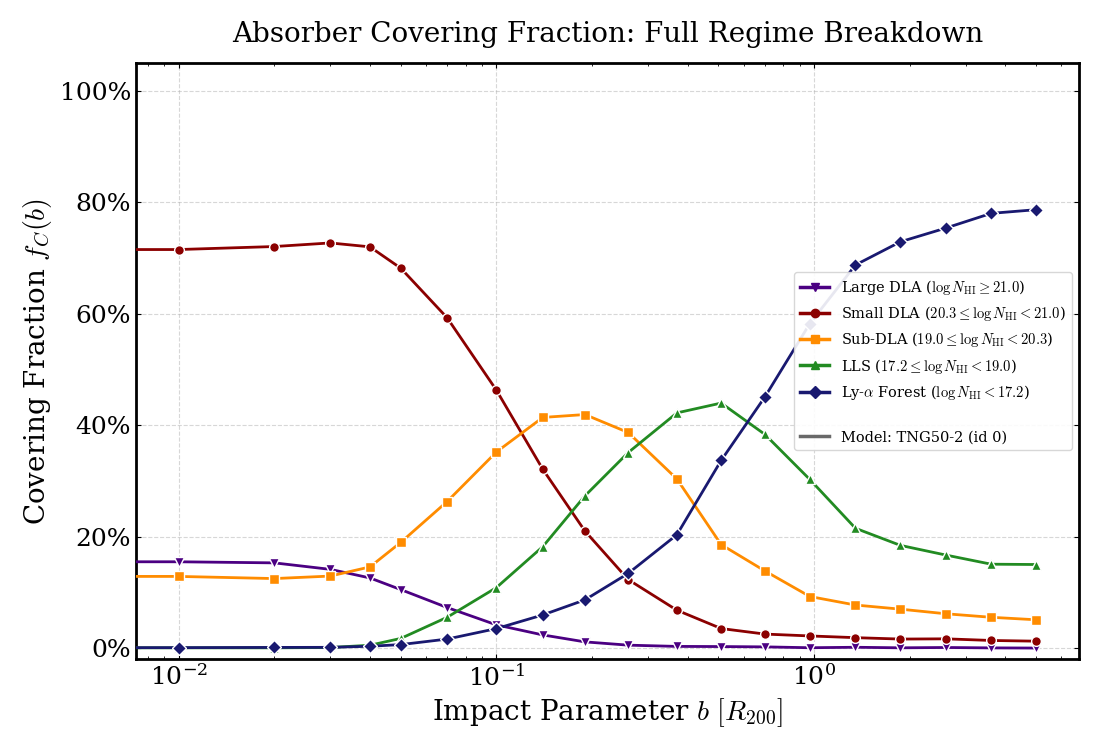

In [15]:
# ==============================================================================
# CELL 3: MULTI-RESOLUTION COVERING FRACTION vs IMPACT PARAMETER (FULL BREAKDOWN)
# ==============================================================================
fig_cov, ax_cov = plt.subplots(figsize=(11, 7.5))

# --- CATEGORY DEFINITIONS ---
# Based on standard N(HI) limits [atoms cm^-2]:
# Lyman-alpha forest : 0 to 1.6e17       (log N < 17.2)
# LLS                : 1.6e17 to 1e19    (17.2 <= log N < 19.0)
# Sub-DLA            : 1e19 to 2e20      (19.0 <= log N < 20.3)
# Small DLA          : 2e20 to 1e21      (20.3 <= log N < 21.0)
# Large DLA          : 1e21 to infinity  (log N >= 21.0)

cat_styles = {
    'Large_DLA': {'color': 'indigo',       'marker': 'v', 'label': r'Large DLA ($\log N_{\mathrm{HI}} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',      'marker': 'o', 'label': r'Small DLA ($20.3 \leq \log N_{\mathrm{HI}} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',   'marker': 's', 'label': r'Sub-DLA ($19.0 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'LLS':       {'color': 'forestgreen',  'marker': '^', 'label': r'LLS ($17.2 \leq \log N_{\mathrm{HI}} < 19.0$)'},
    'Forest':    {'color': 'midnightblue', 'marker': 'D', 'label': r'Ly-$\alpha$ Forest ($\log N_{\mathrm{HI}} < 17.2$)'}
}

# --- EXPLICIT LINE STYLE MAPPING ---
def get_line_style(model_string):
    """Forces explicit line styles based on the TNG resolution identifier."""
    if 'TNG50-2' in model_string: return '-'   # High Res
    if 'TNG50-2_1' in model_string: return '--'  # Med Res
    if 'TNG50-4' in model_string: return ':'   # Low Res
    return '-.' # Fallback

# --- POPULATE AND PLOT DATA ---
for model_name, df_model in dfs_clean.items():
    ls = get_line_style(model_name)
    
    # Initialize empty lists for fractions
    fracs = {key: [] for key in cat_styles.keys()}

    for b_val in unique_radii:
        df_b = df_model[df_model['r_mult_round'] == b_val]
        tot = len(df_b)
        
        if tot > 0:
            nhi = df_b['log_n_hi']
            fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
            fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
            fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
            fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
            fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
        else:
            for key in fracs.keys():
                fracs[key].append(0.0)

    # Plot curves for the current model
    for cat, f_list in fracs.items():
        ax_cov.plot(unique_radii, f_list, color=cat_styles[cat]['color'], lw=2.0, ls=ls, 
                    marker=cat_styles[cat]['marker'], ms=7, mec='white', zorder=4)

# --- COMPOSITE LEGEND ---
# 1. Absorber category legend
legend_elements = [Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], 
                          label=c['label']) for c in cat_styles.values()]
legend_elements.append(Line2D([0], [0], color='none', label=' ')) # Spacer

# 2. Resolution model legend
for model_name in dfs_clean.keys():
    legend_elements.append(Line2D([0], [0], color='dimgray', lw=2.5, 
                                  ls=get_line_style(model_name), label=f'Model: {model_name}'))

# --- AESTHETICS ---
ax_cov.grid(True, ls='--', alpha=0.5)
#ax_cov.set_xlim(-0.1, unique_radii.max() + 0.1)
ax_cov.set_xscale('log')
ax_cov.set_ylim(-0.02, 1.05)
ax_cov.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_cov.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_cov.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_cov.set_title(r'Absorber Covering Fraction: Full Regime Breakdown', pad=15)

ax_cov.legend(handles=legend_elements, loc='center right', frameon=True, 
              fontsize=10.5, edgecolor='lightgray', facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()



In [7]:
# ==============================================================================
# TERMINAL OUTPUT: PERCENTAGE TABLE AT MAX RADIUS
# ==============================================================================
max_b = unique_radii.max()

print("\n" + "="*85)
print(f" ABSORBER FRACTIONS AT IMPACT PARAMETER b = {max_b:.2f} R_200")
print("="*85)
print(f"{'Simulation Model':<20} | {'L-DLA':<9} | {'S-DLA':<9} | {'Sub-DLA':<9} | {'LLS':<9} | {'Forest':<9}")
print("-" * 85)

for model_name, df_model in dfs_clean.items():
    df_b = df_model[df_model['r_mult_round'] == max_b]
    tot = len(df_b)
    
    if tot > 0:
        nhi = df_b['log_n_hi']
        p_ldla = (len(nhi[nhi >= 21.0]) / tot) * 100
        p_sdla = (len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot) * 100
        p_sub  = (len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot) * 100
        p_lls  = (len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot) * 100
        p_for  = (len(nhi[nhi < 17.2]) / tot) * 100
        
        # Clean model name for display (removes the tag inside parentheses if exists)
        model_short = model_name.split('(')[0].strip()
        
        print(f"{model_short:<20} | {p_ldla:>8.2f}% | {p_sdla:>8.2f}% | {p_sub:>8.2f}% | {p_lls:>8.2f}% | {p_for:>8.2f}%")
    else:
        print(f"{model_name:<20} | No data available at this radius.")

print("="*85 + "\n")


 ABSORBER FRACTIONS AT IMPACT PARAMETER b = 5.00 R_200
Simulation Model     | L-DLA     | S-DLA     | Sub-DLA   | LLS       | Forest   
-------------------------------------------------------------------------------------
TNG50-2              |     0.01% |     1.25% |     5.08% |    15.00% |    78.66%



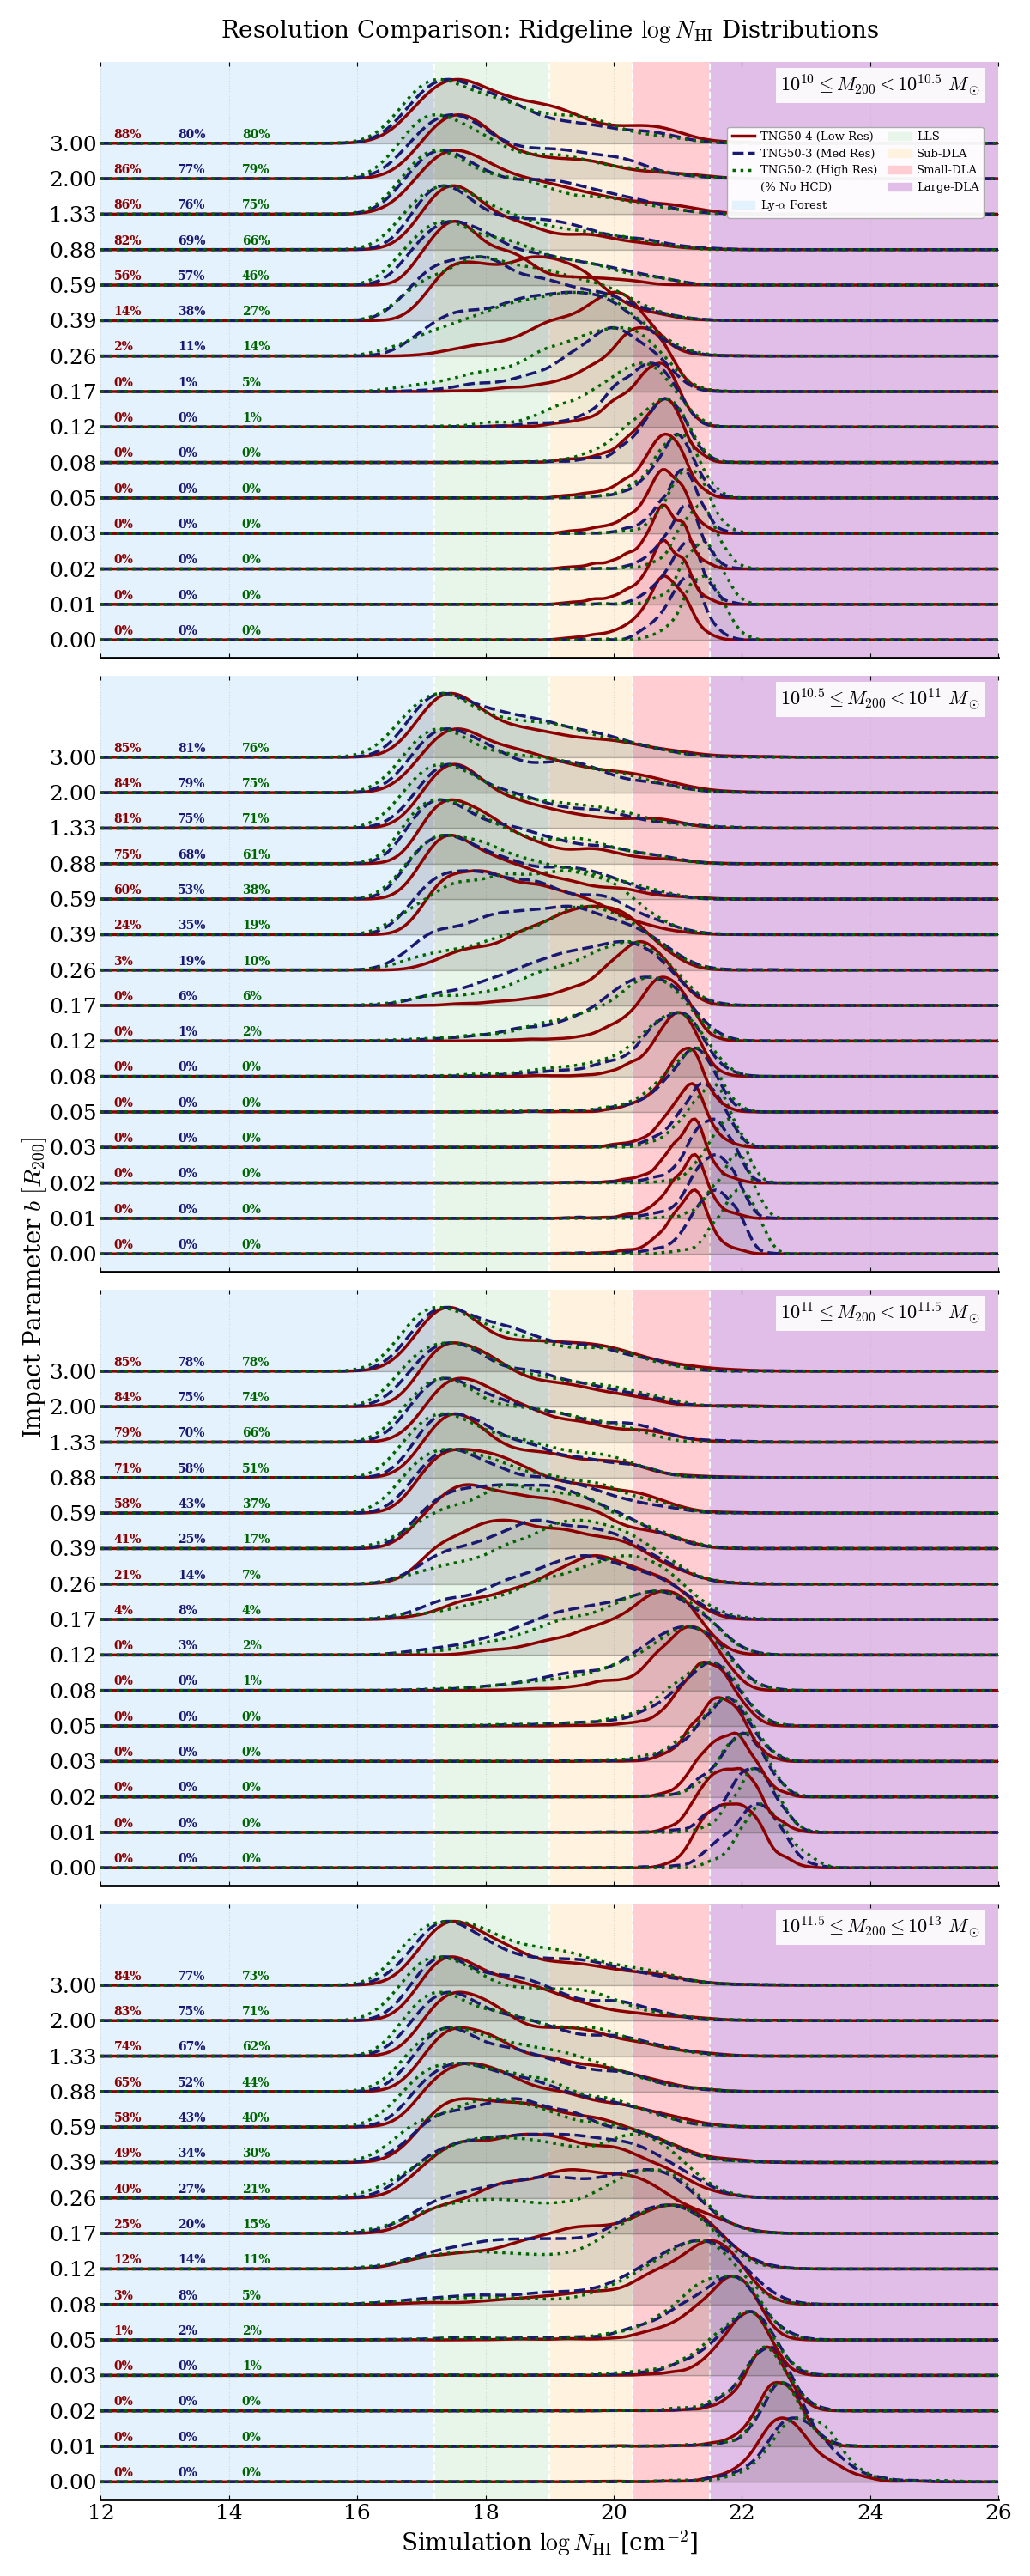

In [ ]:
# ==============================================================================
# CELL 5: RADIAL PROFILES - RIDGELINE PLOT (JOYPLOT)
# ==============================================================================
# 1. Define Adjusted Mass Bins for TNG50
mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**13.0]
mass_labels = [
    r'$10^{10} \leq M_{200} < 10^{10.5} \ M_\odot$',
    r'$10^{10.5} \leq M_{200} < 10^{11} \ M_\odot$',
    r'$10^{11} \leq M_{200} < 10^{11.5} \ M_\odot$',
    r'$10^{11.5} \leq M_{200} \leq 10^{13} \ M_\odot$'
]
n_bins = len(mass_labels)

fig_ridge, axes_ridge = plt.subplots(n_bins, 1, figsize=(12, 7.5 * n_bins), sharex=True)
if n_bins == 1: axes_ridge = np.array([axes_ridge])

colors_pdf  = ['darkred', 'midnightblue', 'darkgreen', 'indigo']
line_styles = ['-', '--', ':', '-.']

c_forest     = '#E3F2FD'  
c_lls        = '#E8F5E9'  
c_subdla     = '#FFF3E0'  
c_smalldla   = '#FFCDD2'  
c_largedla   = '#E1BEE7'  

overlap_factor = 1.8  

for i, (m_low, m_high, m_label) in enumerate(zip(mass_edges[:-1], mass_edges[1:], mass_labels)):
    ax = axes_ridge[i]
    
    # Background Regions
    ax.axvspan(12.0, 17.2, color=c_forest, zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls, zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla, zorder=0)
    ax.axvspan(20.3, 21.5, color=c_smalldla, zorder=0)
    ax.axvspan(21.5, 26.0, color=c_largedla, zorder=0)
    
    ax.axvline(17.2, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(19.0, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(20.3, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(21.5, color='white', ls='--', lw=1.5, zorder=0)
    
    ax.grid(axis='x', ls=':', alpha=0.4)
    ax.grid(axis='y', visible=False) 
    
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    ax.text(0.98, 0.95, m_label, transform=ax.transAxes, fontsize=16, ha='right',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'), zorder=30)

    y_ticks = []
    y_labels = []
    
    for i_b in reversed(range(len(unique_radii))):
        b_val = unique_radii[i_b]
        y_base = i_b  
        
        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)
        
        text_x_start = 12.2 
        
        for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
            c_p = colors_pdf[m_idx % len(colors_pdf)]
            ls  = line_styles[m_idx % len(line_styles)]
            
            df_bin = df_model[(df_model['halo_mass_msun'] >= m_low) & (df_model['halo_mass_msun'] < m_high)]
            df_b = df_bin[df_bin['r_mult_round'] == b_val]
            
            tot = len(df_b)
            df_valid = df_b[df_b['log_n_hi'] > 1.0]
            
            if len(df_valid) > 2:
                kde = gaussian_kde(df_valid['log_n_hi'])
                x_grid = np.linspace(12.0, 26.0, 300)
                pdf = kde(x_grid)
                
                if pdf.max() > 0:
                    pdf_scaled = (pdf / pdf.max()) * overlap_factor
                    ax.plot(x_grid, y_base + pdf_scaled, color=c_p, lw=2.5, ls=ls, zorder=i_b + 5)
                    ax.fill_between(x_grid, y_base, y_base + pdf_scaled, color=c_p, alpha=0.05, zorder=i_b + 4)
            
            if tot > 0:
                p_nohcd = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            else:
                p_nohcd = 0.0
            
            ax.text(text_x_start + (m_idx * 1.0), y_base + 0.15, f"{p_nohcd:.0f}%", 
                    color=c_p, fontsize=10, fontweight='bold', zorder=20)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    if i == 0:
        ax.set_title(r"Resolution Comparison: Ridgeline $\log N_{\rm HI}$ Distributions", pad=20)
        
        custom_lines = [Line2D([0], [0], color=colors_pdf[m_idx % len(colors_pdf)], 
                               lw=2.5, ls=line_styles[m_idx % len(line_styles)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        region_patches = [
            patches.Patch(color=c_forest, label=r'Ly-$\alpha$ Forest'), 
            patches.Patch(color=c_lls, label='LLS'), 
            patches.Patch(color=c_subdla, label='Sub-DLA'),
            patches.Patch(color=c_smalldla, label='Small-DLA'),
            patches.Patch(color=c_largedla, label='Large-DLA')
        ]
        
        custom_lines.append(Line2D([0], [0], marker='none', linestyle='none', label='(% No HCD)'))
        
        leg = ax.legend(handles=custom_lines + region_patches, 
                        loc='upper right', ncol=2, frameon=True, fontsize=9.5,                 
                        bbox_to_anchor=(0.99, 0.9), facecolor='white',            
                        framealpha=0.95, edgecolor='darkgray',        
                        columnspacing=1.0, handletextpad=0.5)            
        leg.set_zorder(100) 

axes_ridge[-1].set_xlabel(r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]")
fig_ridge.text(0.02, 0.5, r'Impact Parameter $b \ [R_{200}]$', va='center', rotation='vertical', fontsize=20)
axes_ridge[-1].set_xlim(12.0, 26.0)

for ax in axes_ridge:
    ax.set_ylim(-0.5, len(unique_radii) + overlap_factor - 0.5)

plt.tight_layout(rect=[0.03, 0.0, 1, 1])
plt.show()


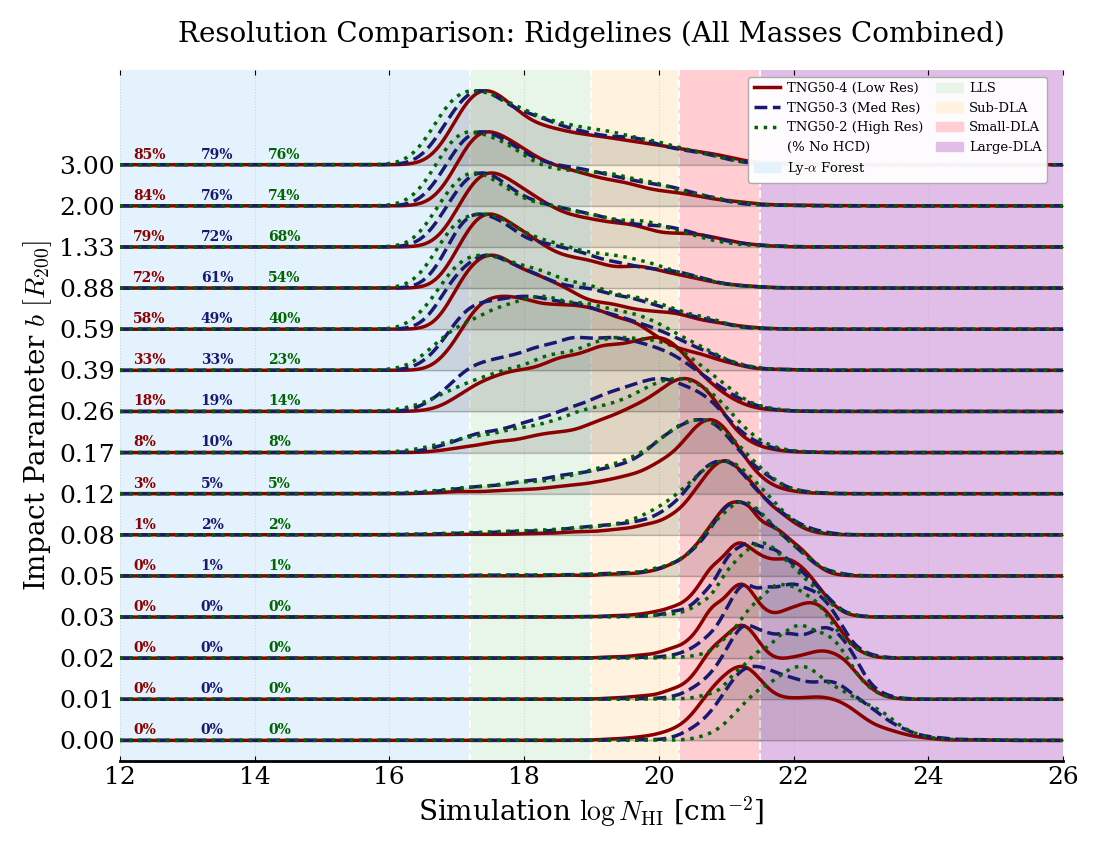

In [ ]:
# ==============================================================================
# CELL 6: RADIAL PROFILES - RIDGELINE PLOT (ALL MASSES COMBINED)
# ==============================================================================
fig_ridge, ax = plt.subplots(figsize=(11, 8.5))

ax.axvspan(12.0, 17.2, color=c_forest, zorder=0)
ax.axvspan(17.2, 19.0, color=c_lls, zorder=0)
ax.axvspan(19.0, 20.3, color=c_subdla, zorder=0)
ax.axvspan(20.3, 21.5, color=c_smalldla, zorder=0)
ax.axvspan(21.5, 26.0, color=c_largedla, zorder=0)

ax.axvline(17.2, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(19.0, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(20.3, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(21.5, color='white', ls='--', lw=1.5, zorder=0)

ax.grid(axis='x', ls=':', alpha=0.4)
ax.grid(axis='y', visible=False) 

ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

y_ticks = []
y_labels = []

for i_b in reversed(range(len(unique_radii))):
    b_val = unique_radii[i_b]
    y_base = i_b  
    
    y_ticks.append(y_base)
    y_labels.append(f"{b_val:.2f}")
    ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)
    
    text_x_start = 12.2 
    
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        
        df_b = df_model[df_model['r_mult_round'] == b_val]
        
        tot = len(df_b)
        df_valid = df_b[df_b['log_n_hi'] > 1.0]
        
        if len(df_valid) > 2:
            kde = gaussian_kde(df_valid['log_n_hi'])
            x_grid = np.linspace(12.0, 26.0, 300)
            pdf = kde(x_grid)
            
            if pdf.max() > 0:
                pdf_scaled = (pdf / pdf.max()) * overlap_factor
                ax.plot(x_grid, y_base + pdf_scaled, color=c_p, lw=2.5, ls=ls, zorder=i_b + 5)
                ax.fill_between(x_grid, y_base, y_base + pdf_scaled, color=c_p, alpha=0.05, zorder=i_b + 4)
        
        if tot > 0:
            p_nohcd = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
        else:
            p_nohcd = 0.0
        
        ax.text(text_x_start + (m_idx * 1.0), y_base + 0.15, f"{p_nohcd:.0f}%", 
                color=c_p, fontsize=10, fontweight='bold', zorder=20)

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)

ax.set_title(r"Resolution Comparison: Ridgelines (All Masses Combined)", pad=20)

custom_lines = [Line2D([0], [0], color=colors_pdf[m_idx % len(colors_pdf)], 
                       lw=2.5, ls=line_styles[m_idx % len(line_styles)], label=model_name) 
                for m_idx, model_name in enumerate(dfs_clean.keys())]

region_patches = [
    patches.Patch(color=c_forest, label=r'Ly-$\alpha$ Forest'), 
    patches.Patch(color=c_lls, label='LLS'), 
    patches.Patch(color=c_subdla, label='Sub-DLA'),
    patches.Patch(color=c_smalldla, label='Small-DLA'),
    patches.Patch(color=c_largedla, label='Large-DLA')
]

custom_lines.append(Line2D([0], [0], marker='none', linestyle='none', label='(% No HCD)'))

leg = ax.legend(handles=custom_lines + region_patches, loc='upper right', ncol=2, frameon=True, fontsize=9.5,                
                bbox_to_anchor=(0.99, 1.0), facecolor='white', framealpha=0.95,              
                edgecolor='darkgray', columnspacing=1.0, handletextpad=0.5)            

leg.set_zorder(100) 

ax.set_xlabel(r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]")
ax.set_ylabel(r'Impact Parameter $b \ [R_{200}]$')
ax.set_xlim(12.0, 26.0)
ax.set_ylim(-0.5, len(unique_radii) + overlap_factor - 0.5)

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# CELL 7: HALO COUNTS PER MASS BIN (UNIQUE HALOS)
# ==============================================================================
print("="*50)
print("             HALO COUNTS PER MASS BIN")
print("="*50)

# Utilizando os mesmos limites de massa das células de plotagem
mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**13.0]
mass_labels_text = [
    '10^10 - 10^10.5',
    '10^10.5 - 10^11',
    '10^11 - 10^11.5',
    '10^11.5 - 10^13'
]

for model_name, df_model in dfs_clean.items():
    # Isola apenas halos únicos (uma linha por halo)
    df_unique = df_model.drop_duplicates(subset=['halo_id']).copy()
    
    # Categoriza a massa de cada halo nos bins definidos
    df_unique['mass_bin'] = pd.cut(df_unique['halo_mass_msun'], bins=mass_edges, labels=mass_labels_text)
    
    # Conta a quantidade de halos em cada categoria
    counts = df_unique['mass_bin'].value_counts(sort=False)
    
    print(f"\nSimulação: {model_name}")
    print(f"Total de halos extraídos: {len(df_unique)}")
    print("-" * 40)
    
    for label, count in counts.items():
        print(f"Bin {label:>15} M_sun : {count:>4} halos")
        
print("\n" + "="*50)

             HALO COUNTS PER MASS BIN

Simulação: TNG50-4 (Low Res)
Total de halos extraídos: 579
----------------------------------------
Bin 10^10 - 10^10.5 M_sun :  106 halos
Bin 10^10.5 - 10^11 M_sun :  163 halos
Bin 10^11 - 10^11.5 M_sun :  147 halos
Bin 10^11.5 - 10^13 M_sun :  163 halos

Simulação: TNG50-3 (Med Res)
Total de halos extraídos: 593
----------------------------------------
Bin 10^10 - 10^10.5 M_sun :  123 halos
Bin 10^10.5 - 10^11 M_sun :  146 halos
Bin 10^11 - 10^11.5 M_sun :  150 halos
Bin 10^11.5 - 10^13 M_sun :  174 halos

Simulação: TNG50-2 (High Res)
Total de halos extraídos: 595
----------------------------------------
Bin 10^10 - 10^10.5 M_sun :  116 halos
Bin 10^10.5 - 10^11 M_sun :  147 halos
Bin 10^11 - 10^11.5 M_sun :  149 halos
Bin 10^11.5 - 10^13 M_sun :  183 halos



COLUMN DENSITY COMPARISON

--- NEW (run0) ---
  Total rows          : 144,585
  Central skewers     : 1,785
  log_n_hi dtype      : float64
  log_n_hi range      : [0.00, 21.72]
  log_n_hi mean       : 15.18
  total_col_den range : [0.000e+00, 5.248e+21]
  total_col_den <= 0  : 32,985  (would give log=-inf)
  log_n_hi NaN        : 0
  log_n_hi Inf        : 0

--- OLD ---
  Total rows          : 108,885
  Central skewers     : 1,785
  log_n_hi dtype      : float64
  log_n_hi range      : [0.00, 25.51]
  log_n_hi mean       : 16.38
  total_col_den range : [0.000e+00, 3.258e+25]
  total_col_den <= 0  : 20,757  (would give log=-inf)
  log_n_hi NaN        : 0
  log_n_hi Inf        : 0



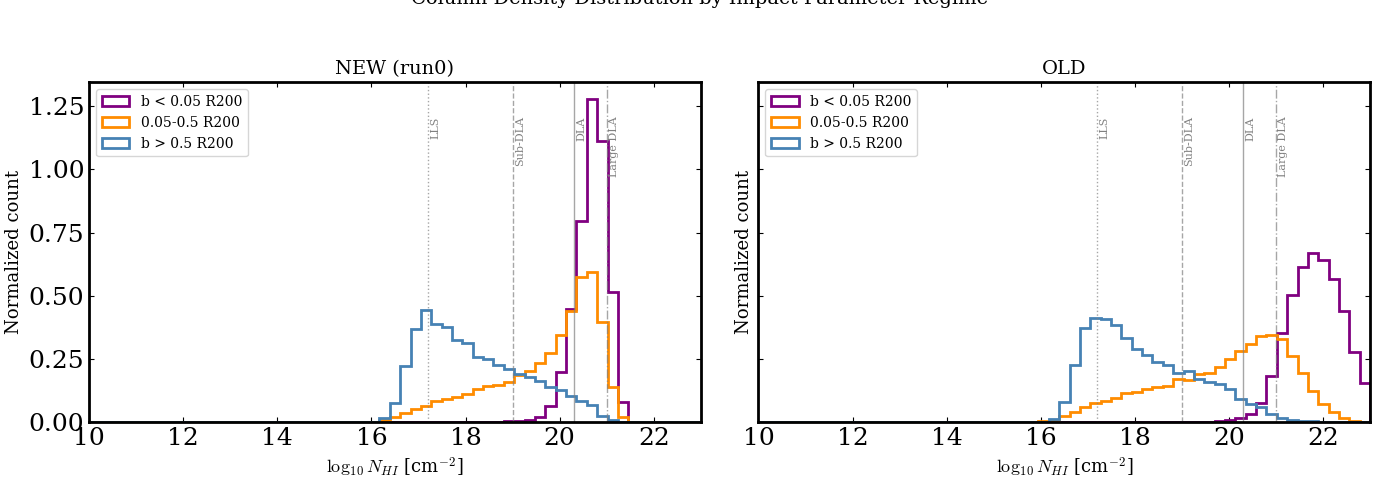

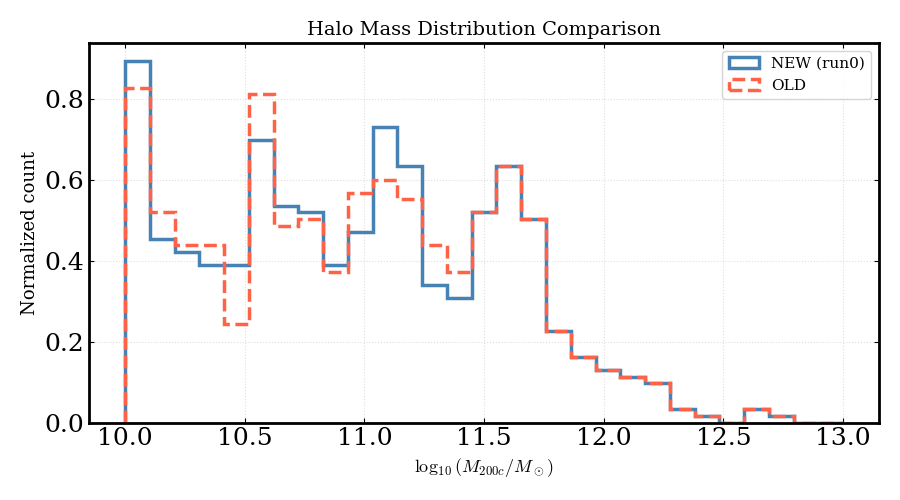

In [19]:
# ==============================================================================
# DIAGNOSTIC CELL — Compare column density distributions between the two runs
# Run this before any covering fraction plot to identify the root cause
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load both dataframes
# Adjust filenames to match what you actually have on disk
df_new = pd.read_pickle("data_for_variance/TNG50-2_z3_595Halos_DLAMode_Stratified_run0_seed42.pkl")
df_old = pd.read_pickle("data_grid/TNG50-2_z3_595Halos_DLAMode_Stratified.pkl")  # old filename

print("=" * 60)
print("COLUMN DENSITY COMPARISON")
print("=" * 60)

for label, df in [("NEW (run0)", df_new), ("OLD", df_old)]:
    # Focus on central skewers only (b ~ 0) to compare like-for-like
    central = df[df['r_multiplier'] == 0.0]
    
    print(f"\n--- {label} ---")
    print(f"  Total rows          : {len(df):,}")
    print(f"  Central skewers     : {len(central):,}")
    print(f"  log_n_hi dtype      : {df['log_n_hi'].dtype}")
    print(f"  log_n_hi range      : [{df['log_n_hi'].min():.2f}, "
          f"{df['log_n_hi'].max():.2f}]")
    print(f"  log_n_hi mean       : {df['log_n_hi'].mean():.2f}")
    print(f"  total_col_den range : [{df['total_col_den'].min():.3e}, "
          f"{df['total_col_den'].max():.3e}]")
    
    # Check for NaN / zero / negative values that could corrupt the log
    n_zero = (df['total_col_den'] <= 0).sum()
    n_nan  = df['log_n_hi'].isna().sum()
    n_inf  = np.isinf(df['log_n_hi']).sum()
    print(f"  total_col_den <= 0  : {n_zero:,}  (would give log=-inf)")
    print(f"  log_n_hi NaN        : {n_nan:,}")
    print(f"  log_n_hi Inf        : {n_inf:,}")

print()

# ------------------------------------------------------------------------------
# Plot the log_n_hi distributions side by side for the SAME impact parameter bin
# This will immediately show if the column densities themselves differ
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

bins_hist = np.linspace(10, 23, 60)

for ax, (label, df) in zip(axes, [("NEW (run0)", df_new), ("OLD", df_old)]):
    # Split by impact parameter regime
    central  = df[df['r_multiplier'] <= 0.05]
    mid      = df[(df['r_multiplier'] > 0.05) & (df['r_multiplier'] <= 0.5)]
    outer    = df[df['r_multiplier'] > 0.5]
    
    for subset, sublabel, color in [
        (central, 'b < 0.05 R200', 'purple'),
        (mid,     '0.05-0.5 R200', 'darkorange'),
        (outer,   'b > 0.5 R200',  'steelblue'),
    ]:
        valid = subset['log_n_hi'].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(valid, bins=bins_hist, histtype='step', 
                label=sublabel, color=color, lw=2, density=True)
    
    # Mark the DLA thresholds
    for thresh, name, ls in [(17.2, 'LLS', ':'), (19.0, 'Sub-DLA', '--'),
                              (20.3, 'DLA', '-'), (21.0, 'Large DLA', '-.')]:
        ax.axvline(thresh, color='gray', ls=ls, lw=1, alpha=0.7)
        ax.text(thresh + 0.05, ax.get_ylim()[1] * 0.9 if ax.get_ylim()[1] > 0 else 1,
                name, fontsize=8, color='gray', rotation=90, va='top')
    
    ax.set_xlabel(r'$\log_{10} N_{HI}$ [cm$^{-2}$]', fontsize=13)
    ax.set_ylabel('Normalized count', fontsize=13)
    ax.set_title(label, fontsize=14)
    ax.legend(fontsize=10)
    ax.set_xlim(10, 23)

plt.suptitle('Column Density Distribution by Impact Parameter Regime', 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# CRITICAL CHECK: Are the halo mass distributions the same?
# If the new run accidentally sampled mostly low-mass halos,
# that alone would suppress Large DLAs (they need massive halos)
# ------------------------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(9, 5))

for label, df, color, ls in [
    ("NEW (run0)", df_new, 'steelblue', '-'),
    ("OLD",        df_old, 'tomato',    '--'),
]:
    # One entry per halo (avoid counting the same halo N_skewers times)
    halo_masses = df.drop_duplicates('halo_id')['halo_mass']
    log_m = np.log10(halo_masses * 1e10)  # convert code units to M_sun
    ax2.hist(log_m, bins=np.linspace(10, 13, 30), histtype='step',
             label=label, color=color, ls=ls, lw=2.5, density=True)

ax2.set_xlabel(r'$\log_{10}(M_{200c} / M_\odot)$', fontsize=13)
ax2.set_ylabel('Normalized count', fontsize=13)
ax2.set_title('Halo Mass Distribution Comparison', fontsize=14)
ax2.legend(fontsize=11)
ax2.grid(True, ls=':', alpha=0.4)
plt.tight_layout()
plt.show()

In [24]:
# ==============================================================================
# SURGICAL DIAGNOSTIC — trace the column density unit chain
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------------------------
# Step 1: Check the n_hi_col arrays directly (pixel-by-pixel column density)
# These are the RAW arrays from fake_spectra, before any summing.
# Units should be cm^-2 per pixel.
# ------------------------------------------------------------------------------
print("=" * 65)
print("STEP 1 — Raw n_hi_col array inspection (per-pixel col. density)")
print("=" * 65)

for label, df in [("NEW", df_new), ("OLD", df_old)]:
    # Sample a single central skewer for inspection
    sample = df[df['r_multiplier'] == 0.0].iloc[0]
    arr = sample['n_hi_col']
    
    print(f"\n  {label}:")
    print(f"    n_hi_col dtype   : {arr.dtype}")
    print(f"    n_hi_col shape   : {arr.shape}")
    print(f"    n_hi_col min/max : {arr.min():.3e}  /  {arr.max():.3e}")
    print(f"    n_hi_col sum     : {arr.sum():.3e}  <- this is total_col_den")
    print(f"    log10(sum)       : {np.log10(arr.sum()):.2f}")
    print(f"    stored log_n_hi  : {sample['log_n_hi']:.2f}")
    
    # Are they consistent?
    recomputed = np.log10(arr.sum()) if arr.sum() > 0 else 0.0
    delta = abs(recomputed - sample['log_n_hi'])
    consistent = "✅ CONSISTENT" if delta < 0.01 else f"❌ MISMATCH by {delta:.3f} dex"
    print(f"    Recomputed vs stored log_n_hi: {consistent}")

# ------------------------------------------------------------------------------
# Step 2: Check if total_col_den == sum(n_hi_col) for ALL rows
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("STEP 2 — Verify total_col_den == sum(n_hi_col) for all rows")
print("=" * 65)

for label, df in [("NEW", df_new), ("OLD", df_old)]:
    # Recompute total from the stored pixel array
    recomputed_total = df['n_hi_col'].apply(np.sum)
    
    ratio = recomputed_total / df['total_col_den'].replace(0, np.nan)
    
    print(f"\n  {label}:")
    print(f"    ratio(recomputed/stored) median : {ratio.median():.4f}")
    print(f"    ratio(recomputed/stored) std    : {ratio.std():.4f}")
    print(f"    ratio(recomputed/stored) range  : "
          f"[{ratio.min():.4f}, {ratio.max():.4f}]")
    
    if abs(ratio.median() - 1.0) < 0.01:
        print(f"    -> ✅ total_col_den is consistent with n_hi_col sum")
    else:
        print(f"    -> ❌ UNIT MISMATCH: total_col_den != sum(n_hi_col)")
        print(f"       Correction factor needed: {ratio.median():.4e}")

# ------------------------------------------------------------------------------
# Step 3: Physical sanity check on pixel values
# For a DLA sightline, peak pixel should be ~10^17-10^20 cm^-2
# (total integral ~10^20-10^22, divided by ~nbins~1000 pixels)
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("STEP 3 — Pixel-level physical sanity check")
print("=" * 65)

for label, df in [("NEW", df_new), ("OLD", df_old)]:
    # Take the 10 most column-dense central skewers
    central = df[df['r_multiplier'] == 0.0].nlargest(10, 'total_col_den')
    
    peak_pixels = central['n_hi_col'].apply(np.max)
    nbins       = central['n_hi_col'].apply(len).iloc[0]
    
    print(f"\n  {label} — top 10 central skewers by col. density:")
    print(f"    nbins per spectrum   : {nbins}")
    print(f"    peak pixel value     : {peak_pixels.mean():.3e} cm^-2")
    print(f"    log10(peak pixel)    : {np.log10(peak_pixels.mean()):.2f}")
    print(f"    Expected (physical)  : ~10^17 to 10^20 cm^-2 per pixel")
    
    if 1e14 < peak_pixels.mean() < 1e22:
        print(f"    -> ✅ Pixel values in physically reasonable range")
    else:
        print(f"    -> ❌ SUSPICIOUS pixel values — likely unit error upstream")

# ------------------------------------------------------------------------------
# Step 4: Check the velocity axis to infer dvbin (pixel width in km/s)
# dvbin is needed to convert col. density per pixel to total
# ------------------------------------------------------------------------------
print("\n" + "=" * 65)
print("STEP 4 — Velocity axis and pixel width")
print("=" * 65)

for label, df in [("NEW", df_new), ("OLD", df_old)]:
    sample  = df.iloc[0]
    vel     = sample['vel_axis']
    dvbin   = vel[1] - vel[0] if len(vel) > 1 else np.nan
    vmax    = vel[-1]
    nbins   = len(vel)
    
    print(f"\n  {label}:")
    print(f"    nbins   : {nbins}")
    print(f"    vmax    : {vmax:.1f} km/s")
    print(f"    dvbin   : {dvbin:.3f} km/s/pixel")

STEP 1 — Raw n_hi_col array inspection (per-pixel col. density)

  NEW:
    n_hi_col dtype   : float32
    n_hi_col shape   : (396,)
    n_hi_col min/max : 0.000e+00  /  0.000e+00
    n_hi_col sum     : 0.000e+00  <- this is total_col_den
    log10(sum)       : -inf
    stored log_n_hi  : 0.00
    Recomputed vs stored log_n_hi: ✅ CONSISTENT

  OLD:
    n_hi_col dtype   : float32
    n_hi_col shape   : (396,)
    n_hi_col min/max : 0.000e+00  /  7.661e+19
    n_hi_col sum     : 1.199e+20  <- this is total_col_den
    log10(sum)       : 20.08
    stored log_n_hi  : 20.08
    Recomputed vs stored log_n_hi: ✅ CONSISTENT

STEP 2 — Verify total_col_den == sum(n_hi_col) for all rows


/tmp/ipykernel_174632/1823705882.py:28: RuntimeWarning: divide by zero encountered in log10
  print(f"    log10(sum)       : {np.log10(arr.sum()):.2f}")



  NEW:
    ratio(recomputed/stored) median : 0.9975
    ratio(recomputed/stored) std    : 0.0116
    ratio(recomputed/stored) range  : [0.9975, 1.9804]
    -> ✅ total_col_den is consistent with n_hi_col sum

  OLD:
    ratio(recomputed/stored) median : 0.9975
    ratio(recomputed/stored) std    : 0.0104
    ratio(recomputed/stored) range  : [0.9975, 1.9178]
    -> ✅ total_col_den is consistent with n_hi_col sum

STEP 3 — Pixel-level physical sanity check

  NEW — top 10 central skewers by col. density:
    nbins per spectrum   : 396
    peak pixel value     : 1.558e+21 cm^-2
    log10(peak pixel)    : 21.19
    Expected (physical)  : ~10^17 to 10^20 cm^-2 per pixel
    -> ✅ Pixel values in physically reasonable range

  OLD — top 10 central skewers by col. density:
    nbins per spectrum   : 396
    peak pixel value     : 6.987e+24 cm^-2
    log10(peak pixel)    : 24.84
    Expected (physical)  : ~10^17 to 10^20 cm^-2 per pixel
    -> ❌ SUSPICIOUS pixel values — likely unit error upst

In [26]:
# ==============================================================================
# SELF-CONTAINED VERIFICATION TEST — no external dependencies
# Run this in the notebook AFTER applying the filter_mode="None" fix in utils.py
# ==============================================================================
import numpy as np
import h5py
import os
import sys

sys.path.append("/home/vroberto/FakeSpectra_DLAs/tools")
import utils
import radii_skewers

# --- Configuration (same as the main script) ---
BASE_PATH = "/home/STORAGE/TNG50-2"
SNAP_NUM  = 25
SIM_TYPE  = "TNG"

# --- Find one massive halo directly from the catalog ---
# We pick the single most massive halo in the snapshot as a stress test.
# A massive halo at b=0 should always give log_n_hi ~ 20-22.
group_dir = os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}")
file0     = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")

print("Scanning catalog for the most massive halo...")
best_mass    = 0.0
best_halo_id = 0
current_offset = 0

with h5py.File(file0, 'r') as f:
    num_files = int(f['Header'].attrs['NumFiles'])

for i in range(num_files):
    fpath = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.{i}.hdf5")
    if not os.path.exists(fpath):
        continue
    with h5py.File(fpath, 'r') as f:
        if 'Group' not in f or 'Group_M_Crit200' not in f['Group']:
            continue
        masses     = f['Group']['Group_M_Crit200'][:]
        local_best = np.argmax(masses)
        if masses[local_best] > best_mass:
            best_mass    = masses[local_best]
            best_halo_id = current_offset + local_best
        current_offset += len(masses)

print(f"Most massive halo: ID={best_halo_id}, "
      f"log M = {np.log10(best_mass * 1e10):.2f} M_sun")

# --- Run the extraction on the central skewer only ---
ctx         = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
halo_finder = utils.HaloFinder(ctx)
halo_info   = halo_finder.get_halo_properties(best_halo_id)
geom        = radii_skewers.SkewerGeometry(ctx, halo_info)

skewers_central = geom.generate_skewers(r_multiplier=0.0)
results         = geom.run_analysis_batched(skewers_central)

# --- Report ---
print(f"\n{'='*55}")
print(f"VERIFICATION RESULTS (filter_mode should be 'None')")
print(f"{'='*55}")
print(f"Halo ID     : {best_halo_id}")
print(f"log M_200c  : {np.log10(best_mass * 1e10):.2f} M_sun")
print(f"R200        : {halo_info['r200']:.4f} code units")
print()

all_ok = True
for r in results:
    log_n = r['log_n_hi']
    total = r['total_col_den']
    
    # Physical expectation for a massive halo at b=0: 20 < log_n_hi < 23
    status = "✅" if 18.0 < log_n < 23.0 else "❌ UNEXPECTED"
    if "❌" in status:
        all_ok = False
    
    print(f"  axis={r['axis_name']}  "
          f"log_n_hi={log_n:.2f}  "
          f"total_col_den={total:.3e}  {status}")

print()
if all_ok:
    print("✅ Fix confirmed — column densities are physically reasonable.")
    print("   Safe to launch the 5 full runs.")
else:
    print("❌ Something is still wrong — do NOT launch the full runs yet.")
    print("   Check that filter_mode='None' was saved in utils.py.")

Scanning catalog for the most massive halo...
Most massive halo: ID=0, log M = 12.78 M_sun
--> [Halo 0] Extracting batch of 3 Skewers in RAM...

VERIFICATION RESULTS (filter_mode should be 'None')
Halo ID     : 0
log M_200c  : 12.78 M_sun
R200        : 432.7388 code units

  axis=X  log_n_hi=0.00  total_col_den=0.000e+00  ❌ UNEXPECTED
  axis=Y  log_n_hi=19.92  total_col_den=8.334e+19  ✅
  axis=Z  log_n_hi=21.16  total_col_den=1.451e+21  ✅

❌ Something is still wrong — do NOT launch the full runs yet.
   Check that filter_mode='None' was saved in utils.py.


In [47]:
# Pegue o halo mais massivo do NEW dataset
df_new = pd.read_pickle("data_for_variance/TNG50-2_z3_595Halos_DLAMode_Stratified_run0_seed42.pkl")
df_central = df_new[df_new['r_multiplier'] == 0.0]
df_massive = df_central[df_central['halo_mass']*1e10/0.6774 > 10**11.5]

# Para cada sightline central, pegue o pixel mais denso e veja
# quantos pixels adjacentes acima de 10^17 cm^-2 ele tem
for idx, row in df_massive.head(5).iterrows():
    n_hi = row['n_hi_col']
    above_thresh = n_hi > 10**17
    if np.any(above_thresh):
        from itertools import groupby
        from operator import itemgetter
        runs = []
        for k, g in groupby(enumerate(above_thresh), key=itemgetter(1)):
            if k:
                grp = list(map(itemgetter(0), g))
                runs.append(len(grp))
        print(f"Halo {row['halo_id']}, log M={np.log10(row['halo_mass']*1e10/0.6774):.2f}, "
              f"log N_HI={row['log_n_hi']:.2f}, runs above 10^17: {runs}")
    else:
        print("did not work")

did not work
Halo 0, log M=12.95, log N_HI=19.92, runs above 10^17: [2, 1]
Halo 0, log M=12.95, log N_HI=21.16, runs above 10^17: [3]
Halo 1, log M=12.78, log N_HI=17.86, runs above 10^17: [2]
Halo 1, log M=12.78, log N_HI=20.97, runs above 10^17: [2]


In [48]:
df_massive.head(5)

,halo_id,halo_mass,halo_r200_mpc,redshift,skewer_id,axis,r_multiplier,impact_kpc,log_n_hi,total_col_den,...,mean_wave,mean_vel,vel_coherent,vel_peak_shift,wave,flux,vel_axis,vel_aligned,chi_axis,n_hi_col
111294,0,602.084045,432.738800,3.008131,1,0,0.0,0.0,0.000000,0.000000e+00,...,1215.670000,0.000000,0.000000,0.000000,"[1207.6643, 1207.7047, 1207.7451, 1207.7855, 1...","[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...","[-1980.773, -1970.7438, -1960.7145, -1950.6853...","[-1980.773, -1970.7438, -1960.7145, -1950.6853...","[-17500.0, -17411.393, -17322.785, -17234.178,...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
111295,0,602.084045,432.738800,3.008131,2,1,0.0,0.0,19.920839,8.333727e+19,...,1215.820486,37.108487,-5.553014,60.175381,"[1207.6643, 1207.7047, 1207.7451, 1207.7855, 1...","[0.9427781, 0.9428132, 0.94284594, 0.9428482, ...","[-1980.773, -1970.7438, -1960.7145, -1950.6853...","[-2040.9484, -2030.9191, -2020.8899, -2010.860...","[-17500.0, -17411.393, -17322.785, -17234.178,...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
111296,0,602.084045,432.738800,3.008131,3,2,0.0,0.0,21.161692,1.451082e+21,...,1215.637982,-7.896055,0.164835,-165.482299,"[1207.6643, 1207.7047, 1207.7451, 1207.7855, 1...","[0.010884742, 0.014457336, 0.020933004, 0.0283...","[-1980.773, -1970.7438, -1960.7145, -1950.6853...","[-1815.2906, -1805.2615, -1795.2322, -1785.203...","[-17500.0, -17411.393, -17322.785, -17234.178,...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
144342,1,404.227448,378.910309,3.008131,1,0,0.0,0.0,17.855734,7.173548e+17,...,1215.566467,-25.532931,-3.488099,-5.014615,"[1207.6643, 1207.7047, 1207.7451, 1207.7855, 1...","[0.9992956, 0.99929434, 0.9992906, 0.9992863, ...","[-1980.773, -1970.7438, -1960.7145, -1950.6853...","[-1975.7583, -1965.7291, -1955.7, -1945.6707, ...","[-17500.0, -17411.393, -17322.785, -17234.178,...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
144343,1,404.227448,378.910309,3.008131,2,1,0.0,0.0,20.966324,9.253892e+20,...,1216.005956,82.837507,-15.818679,215.628450,"[1207.6643, 1207.7047, 1207.7451, 1207.7855, 1...","[0.48517877, 0.4872106, 0.49058008, 0.4938318,...","[-1980.773, -1970.7438, -1960.7145, -1950.6853...","[-2196.4014, -2186.3723, -2176.343, -2166.3137...","[-17500.0, -17411.393, -17322.785, -17234.178,...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


In [49]:
lista = np.where(df_central['halo_mass']*1e10/0.6774 > 10**11.5)
print(np.array(lista[0]).shape, np.array(df_central['halo_mass']*1e10/0.6774).shape)

(537,) (1785,)
